In [ ]:
# ============================================================================
# 🔧 Environment Setup and Initialization
# ============================================================================

from PIL import Image
import time
import re
import json
import concurrent.futures
import matplotlib.pyplot as plt

from demo.patho_agenticrag import MyAgent
from demo.vrag_agent import VRAG



🔧 Initialize VRAG...
🤖 Initialize MyAgent...
🖼️ Loading image...
✅ Image loaded: (2048, 1646)


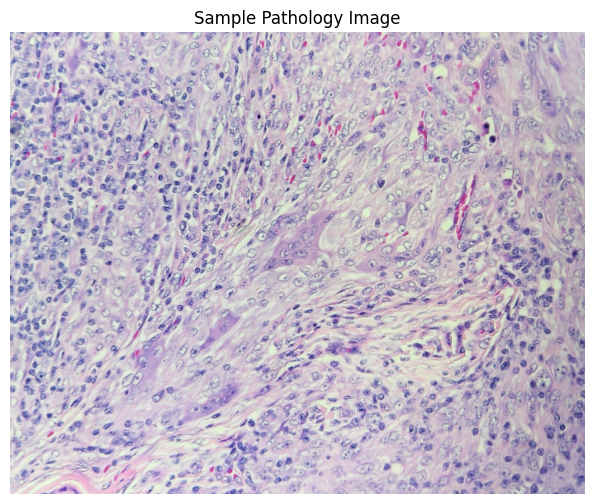

📝 Sample query from pathmmu_test index3740:
Ground truth: C

What does the presence of multinucleate cells resembling osteoclast-like cells suggest in this context?

A. Liposarcoma
B. Basal cell carcinoma
C. Benign fibrous histiocytoma
D. Osteosarcoma




In [ ]:
# ============================================================================
# ⚙️ Configuration and Component Initialization
# ============================================================================

# Model configuration
LLM_CONFIG = {
    "model": "Agent-Router",
    "model_server": "http://localhost:8032/v1",
    "api_key": "EMPTY",
}

# Expert model URL
PATHO_R1_URL = "http://localhost:8018/v1/chat/completions"

# Sample image path
SAMPLE_IMAGE_PATH = "images/demo.jpg"

# Sample query
SAMPLE_QUERY = """
What does the presence of multinucleate cells resembling osteoclast-like cells suggest in this context?

A. Liposarcoma
B. Basal cell carcinoma
C. Benign fibrous histiocytoma
D. Osteosarcoma
"""

print("🔧 Initialize VRAG...")
rag = VRAG()

print("🤖 Initialize MyAgent...")
agent = MyAgent(
    qwen_cfg=LLM_CONFIG,
    rag=rag,
    patho_r1_url=PATHO_R1_URL
)

# Load sample image
print("🖼️ Loading image...")
try:
    image = Image.open(SAMPLE_IMAGE_PATH)
    print(f"✅ Image loaded: {image.size}")
    
    # Display image
    plt.figure(figsize=(8, 6))
    plt.imshow(image)
    plt.title("Sample Pathology Image")
    plt.axis('off')
    plt.show()
    
except Exception as e:
    print(f"❌ Image load failed: {e}")
    print("Using dummy image...")
    # Create dummy image
    image = Image.new('RGB', (400, 300), color='lightgray')


print("📝 Sample query from pathmmu_test index3740:")
print("Ground truth: C")
print(SAMPLE_QUERY)



In [46]:
# ============================================================================
# 🚀 Start Step-by-Step Demo - Initialize Variables
# ============================================================================

# Record start time
start_time = time.time()
timeout = 120  # Total timeout

# Initialize result storage variables
tool_output = None
rag_results = []
context = None
final_answer = None
agent_stats = {}

print("🚀 Starting pathology AI agent...")
print("=" * 60)


🚀 Starting pathology AI agent...


In [54]:
# ============================================================================
# 📝 Step 1: Tool Decision (based on MyAgent.tool method)
# ============================================================================


print("📝 Step 1: Tool Decision")
print("-" * 30)


print("🤖 Calling Agentic Router for tool decision...")
step1_start = time.time()

# Call agent tool method
tool_output = agent.tool(SAMPLE_QUERY, image)

print(f"✅ Tool decision complete")
print(f"📝 Result length: {len(tool_output)} chars")
print("-" * 50)
print("🔍 Tool decision result:")
print(tool_output)
print("-" * 50)
        


📝 Step 1: Tool Decision
------------------------------
🤖 Calling Agentic Router for tool decision...
✅ Tool decision complete
📝 Result length: 1738 chars
--------------------------------------------------
🔍 Tool decision result:
<think> The user is asking about the presence of multinucleate cells with features of osteoclast-like cells, which is a critical diagnostic clue in identifying certain pathological processes, particularly those involving bone or related tissues. The correct answer depends on understanding the association between the presence of such cells and the specific characteristics of each listed condition. Osteoclast-like cells are typically involved in bone resorption and are more commonly associated with active bone-related diseases or neoplasms. Therefore, the presence of these cells would be more indicative of conditions like osteosarcoma or other lesions involving the skeletal system rather than the other options listed.

To make an accurate determination, it is nec

In [60]:
# ============================================================================
# 🔍 Step 2: Parse Tool Calls (based on MyAgent.run logic)
# ============================================================================

print("🔍 Step 2: Parse Tool Calls")
print("-" * 30)

# Extract <tool_call> section and parse (consistent with MyAgent.run method)
tool_call_match = re.search(
    r"<tool_call>\s*(.*?)\s*</tool_call>", tool_output, re.DOTALL
)

rag_queries = []
partition = None

if tool_call_match:
    raw_content = tool_call_match.group(1).strip()
    print(f"📋 Found tool call content: {len(raw_content)} chars")
    print("-" * 30)
    print("🔍 Raw tool call content:")
    print(raw_content)
    print("-" * 30)
    
    print("📋 Parsing tool calls:")
    
    for i, line in enumerate(raw_content.splitlines(), 1):
        line = line.strip()
        if not line:
            print(f"  {i:2d}. (empty line)")
            continue
            
        print(f"  {i:2d}. Parsing: {line}")
        
        try:
            call = json.loads(line)
            print(f"      ✅ JSON parsed: {call}")
            
            # collect RAG queries (consistent with MyAgent.run method)
            if call.get("name") == "rag":
                q = call.get("parameters", {}).get("query")
                if q:
                    rag_queries.append(q)
                    print(f"      📚 RAG query: {q}")
                    
            # also capture partition if there's a classifier call
            if call.get("name") == "classifier":
                partition = call.get("parameters", {}).get("partition")
                print(f"      🏷️ Classifier partition: {partition}")
                
        except json.JSONDecodeError as e:
            print(f"      ❌ JSON parse failed: {e}")
            
else:
    print("❌ No valid <tool_call> tags found")

print(f"\n📊 Parse results:")
print(f"  📚 RAG queries: {len(rag_queries)}")
for i, q in enumerate(rag_queries, 1):
    print(f"    {i}. {q}")
print(f"  🏷️ Classifier partition: {partition}")


🔍 Step 2: Parse Tool Calls
------------------------------
📋 Found tool call content: 346 chars
------------------------------
🔍 Raw tool call content:
{"name": "rag", "parameters": {"query": "What is the histological and diagnostic significance of the presence of multinucleate cells resembling osteoclast-like cells in the context of liposarcoma, basal cell carcinoma, benign fibrous histiocytoma, and osteosarcoma?"}}  
{"name": "classifier", "parameters": {"partition": "Bone_and_Soft_Tissue"}}
------------------------------
📋 Parsing tool calls:
   1. Parsing: {"name": "rag", "parameters": {"query": "What is the histological and diagnostic significance of the presence of multinucleate cells resembling osteoclast-like cells in the context of liposarcoma, basal cell carcinoma, benign fibrous histiocytoma, and osteosarcoma?"}}
      ✅ JSON parsed: {'name': 'rag', 'parameters': {'query': 'What is the histological and diagnostic significance of the presence of multinucleate cells resembling 

In [61]:
# ============================================================================
# 🔎 Step 3: RAG Knowledge Retrieval (based on MyAgent.run logic)
# ============================================================================

print("🔎 Step 3: RAG Knowledge Retrieval")
print("-" * 30)

# Concurrent RAG and generator calls (consistent with MyAgent.run method)
rag_results = []

if rag_queries:
    print(f"🚀 Starting concurrent retrieval for {len(rag_queries)} queries...")
    print("-" * 30)
    
    def process_rag_query(q):
        """Process single RAG query (consistent with MyAgent.run internal function)"""
        query_start = time.time()
        print(f"  🔍 Starting query: '{q[:50]}...'")
        
        try:
            rag_output = agent.rag.run(q, image, partition)
            result = agent.get_rag_answer_from_generator(rag_output)
            query_time = time.time() - query_start
            
            print(f"  ✅ Query complete: '{q[:30]}...'")
            print(f"      📝 Result length: {len(result) if result else 0} chars")
            if result:
                print(f"      📄 Preview: {result[:100]}...")
            
            return (q, result)
        except Exception as e:
            query_time = time.time() - query_start
            print(f"  ❌ Query failed: '{q[:30]}...'")
            print(f"      🚨 Error: {e}")
            return (q, None)
    
    print("📋 Executing all RAG queries concurrently:")
    
    # Execute all queries concurrently (consistent with MyAgent.run method)
    with concurrent.futures.ThreadPoolExecutor() as executor:
        futures = {
            executor.submit(process_rag_query, q): q for q in rag_queries
        }
        # No timeout, let RAG queries complete naturally
        for future in concurrent.futures.as_completed(futures):
            rag_results.append(future.result())
    
    print(f"\n📊 RAG retrieval summary:")
    successful_count = sum(1 for _, result in rag_results if result)
    print(f"  ✅ Successful: {successful_count}/{len(rag_results)}")
    
    for i, (query, result) in enumerate(rag_results, 1):
        status = "✅" if result else "❌"
        length = len(result) if result else 0
        print(f"    {i}. {status} '{query[:40]}...' -> {length} chars")
        
else:
    print("ℹ️ No RAG retrieval needed (no RAG queries found)")


🔎 Step 3: RAG Knowledge Retrieval
------------------------------
🚀 Starting concurrent retrieval for 1 queries...
------------------------------
📋 Executing all RAG queries concurrently:
  🔍 Starting query: 'What is the histological and diagnostic significan...'
  ✅ Query complete: 'What is the histological and d...'
      📝 Result length: 1770 chars
      📄 Preview: The histological and diagnostic significance of the presence of multinucleate cells resembling osteo...

📊 RAG retrieval summary:
  ✅ Successful: 1/1
    1. ✅ 'What is the histological and diagnostic ...' -> 1770 chars


In [68]:
# ============================================================================
# 🧠 Step 4: Expert Model Inference (based on MyAgent.call_specialist_model)
# ============================================================================

print("🧠 Step 4: Expert Model Inference")
print("-" * 30)

# Process RAG results and build context
useful_contexts = []

for i, (q, rag_result) in enumerate(rag_results, 1):
    # Check for valid results
    if rag_result:
        # Format and add to context
        formatted_context = f"Q: {q}\nA: {rag_result}"
        useful_contexts.append(formatted_context)

# Merge context
if useful_contexts:
    context = "\n\n".join(useful_contexts)
    print(f"\n📊 Merged context:")
    print(f"  📚 Valid contexts: {len(useful_contexts)}")
    print(f"  📝 Total length: {len(context)} chars")
    print(f"  📄 Context preview:")
    print("-" * 40)
    print(context[:300] + "..." if len(context) > 300 else context)
    print("-" * 40)
else:
    context = None
    print(f"\n📊 Context merge result:")
    print("  ℹ️ No valid context, using empty context")

print(f"\n🤖 Calling expert model...")
print("📤 Sending to expert model:")
print(f"  📝 Query length: {len(SAMPLE_QUERY)} chars")
print(f"  🖼️ Image size: {image.size}")
print(f"  📚 Context length: {len(context) if context else 0} chars")

step6_start = time.time()

try:
    # Call expert model
    final_answer = agent.call_specialist_model(SAMPLE_QUERY, image, context=context)
    
    step6_time = time.time() - step6_start
    
    print(f"\n🎯 Expert model output:")
    print("="*80)
    print(final_answer)
    print("="*80)
    
except Exception as e:
    step6_time = time.time() - step6_start
    print(f"\n❌ Expert model inference failed")
    print(f"🚨 Error: {e}")
    final_answer = f"Expert model call failed: {str(e)}"


🧠 Step 4: Expert Model Inference
------------------------------

📊 Merged context:
  📚 Valid contexts: 1
  📝 Total length: 2001 chars
  📄 Context preview:
----------------------------------------
Q: What is the histological and diagnostic significance of the presence of multinucleate cells resembling osteoclast-like cells in the context of liposarcoma, basal cell carcinoma, benign fibrous histiocytoma, and osteosarcoma?
A: The histological and diagnostic significance of the presence of multi...
----------------------------------------

🤖 Calling expert model...
📤 Sending to expert model:
  📝 Query length: 193 chars
  🖼️ Image size: (2048, 1646)
  📚 Context length: 2001 chars

🎯 Expert model output:
<think>The multinucleate cells resembling osteoclast-like cells in the image must be interpreted in the context of the tumor type. According to the provided knowledge, these cells are generally absent in osteosarcoma tumor bone, making their presence a key feature that can help exclude osteo